# EATS PL Report - Satellites
Template by André Moitinho

***

### Student number: 56669
### Name: André Cardoso

***

<div class="alert alert-block alert-info">
    
## Instructions

* Fill in your name and number above
* This template provides blocks of instructions that guide you through the activity and report. Put your codes and comments below the corresponding blocks. 
* Add as many code and markdown cells as necessary. 
* The blue background colour in the markdown cells (like this one) is reserved for the instruction blocks. Use white cells for your comments.
* Write a clear report:
    * Provide justifications and comments.
    * Figures and labels (legends, axes, etc) should be easy to read.
    * Tables should be neatly formatted and include labels.

**To submit your report:**

You will need to have the nbconvert[webpdf] package installed for saving to pdf. <br>
Anaconda: conda install -c conda-forge nbconvert-webpdf <br>
General: pip install nbconvert[webpdf]
    
* Clean up and make sure all works well: In the "Kernel" menu select "Restart & Run All" (or use the "fast forward/double arrow" icon). Wait until the process is completed
* Save to a pdf file:
    * JupyterNotebook users: In the "File" menu -> "Download As" -> "**PDF via HTML (.html)**". 
    * JupyterLab users: In the "File" menu -> "Save and Export Notebook As" -> "**Webpdf**".
* Check that the PDF file is fine (no truncated lines, nothing missing, etc)
* Name the file: NumberFirstnameLastname.pdf* (e.g. 10101ClaudeShannon.pdf)
* Upload the pdf file to the "PL Report - Satellites" assignement area. 

### Tips
* Run a cell  - keyboard shortcut: shift-enter
* To create "markdown" cells like this one, For comments, not for code: create a new cell. In the menu above to the right of the "fast-forward" icon there's a dropdown button with the default value "Code". Change to "Markdown".
* To display an image from a file on disk (e.g. image.png): In a **markdown cell** you can use *\!\[some text\](image.png)*, or simply drag and drop!
</div>

---

<div class="alert alert-block alert-info">  

## Setup
Put all your imports (e.g. ephem, numpy, matplotlib, etc)  in the cell bellow
</div>


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from mpl_toolkits.mplot3d import axes3d  
import ephem
import datetime
import csv

<div class="alert alert-block alert-info">  

## <center>PART 1 -  Orbital elements basics </center>


In this first exercise, you'll import a _Three Line Element_ (TLE) for an Earth satellite, propagate its orbit with SGP4 (Simplified perturbations models) implemented in _ephem_ and plot the results. In the process you will see which methods and attributes are provided by _ephem_ for dealing with Earth satellites and their observation.

---

### Set observer's coordinates and time

Start by setting the observer's coordinates and time in an _ephem Observer_ object. Say which place and time you chose.
    
</div>

Para as coordenadas utilizou-se a sede da LusoSpace no Areeiro no dia 20/11/2026

In [84]:
obs = ephem.Observer()
obs.lat = np.deg2rad(38.74446901694215)
obs.long = np.deg2rad(-9.128535641602733)
obs.date = datetime.datetime.today()

<div class="alert alert-block alert-info">  
    
What attributes and methods does the _Observer_ object provide? Use the "help" command and show the output

</div>

In [4]:
help(obs)

Help on Observer in module ephem object:

class Observer(_libastro.Observer)
 |  A location on earth for which positions are to be computed.
 |
 |  An `Observer` instance allows you to compute the positions of
 |  celestial bodies as seen from a particular latitude and longitude on
 |  the Earth's surface.  The constructor takes no parameters; instead,
 |  set its attributes once you have created it.  Defaults:
 |
 |  `date` - the moment the `Observer` is created
 |  `lat` - zero latitude
 |  `lon` - zero longitude
 |  `elevation` - 0 meters above sea level
 |  `horizon` - 0 degrees
 |  `epoch` - J2000
 |  `temp` - 15 degrees Celsius
 |  `pressure` - 1010 mBar
 |
 |  Method resolution order:
 |      Observer
 |      _libastro.Observer
 |      builtins.object
 |
 |  Methods defined here:
 |
 |  __copy__ = copy(self)
 |
 |  __repr__(self)
 |      Return a useful textual representation of this Observer.
 |
 |  compute_pressure(self)
 |      Set the atmospheric pressure for the current ele

<div class="alert alert-block alert-info">  

### Read a TLE

From the TLE file provided for this exercise, select a satellite and load its orbital elements into an ephem _EarthSatellite_ object (readtle).

</div>

Escolheu-se o Posat-2 lançado pela LusoSpace

In [75]:
file = open("3le_03112026.txt")
f_lines = file.readlines()

line = 74245
lines = []
for i in range(3):
    lines.append(f_lines[line-1 + i])
file.close()

posat2 = ephem.readtle(lines[0], lines[1], lines[2] )

<div class="alert alert-block alert-info">  
    
What attributes and methods does the _EarthSatellite_ object provide? Use the "help" command and show the output

</div>

In [6]:
help(posat2)

Help on EarthSatellite object:

class EarthSatellite(Body)
 |  A satellite in orbit around the Earth, usually built by passing the text of a TLE entry to the `ephem.readtle()` routine. You can read and write its orbital parameters through the following attributes:
 |
 |  _ap -- argument of perigee at epoch (degrees)
 |  _decay -- orbit decay rate (revolutions per day-squared)
 |  _drag -- object drag coefficient (per earth radius)
 |  _e -- eccentricity
 |  _epoch -- reference epoch (mjd)
 |  _inc -- inclination (degrees)
 |  _M -- mean anomaly (degrees from perigee at epoch)
 |  _n -- mean motion (revolutions per day)
 |  _orbit -- integer orbit number of epoch
 |  _raan -- right ascension of ascending node (degrees)
 |
 |  Method resolution order:
 |      EarthSatellite
 |      Body
 |      builtins.object
 |
 |  Methods defined here:
 |
 |  __init__(self, /, *args, **kwargs)
 |      Initialize self.  See help(type(self)) for accurate signature.
 |
 |  -------------------------------

<div class="alert alert-block alert-info">  
    
List the attributes and methods in the _EarthSatellite_  by directly inspecting its contents with the _dir_ instruction.
    
</div>

In [7]:
attributes = dir(posat2)
print(attributes)

['M', '_M', '__class__', '__copy__', '__delattr__', '__dir__', '__doc__', '__eq__', '__format__', '__ge__', '__getattribute__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__lt__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__sizeof__', '__str__', '__subclasshook__', '_ap', '_decay', '_drag', '_e', '_epoch', '_inc', '_n', '_orbit', '_raan', 'a_dec', 'a_epoch', 'a_ra', 'alt', 'ap', 'az', 'catalog_number', 'circumpolar', 'compute', 'copy', 'dec', 'decay', 'drag', 'e', 'eclipsed', 'elevation', 'elong', 'epoch', 'g_dec', 'g_ra', 'ha', 'inc', 'mag', 'n', 'name', 'neverup', 'orbit', 'parallactic_angle', 'ra', 'raan', 'radius', 'range', 'range_velocity', 'rise_az', 'rise_time', 'set_az', 'set_time', 'size', 'sublat', 'sublong', 'transit_alt', 'transit_time', 'writedb']


<div class="alert alert-block alert-info">  
    
### Orbit integration.
    
Our goal is to visualise the satellite's positions (alititude and azimuth) for an array of times.

1. Create an array of times spanning a whole day
2. Compute the orbits for each time in the array


</div>


In [132]:
midnight = datetime.datetime.replace(datetime.datetime.now(), hour=0)

times = []
timestep = 0.02

#Cria um array de datas com intervalo de timestep em minutos
for i in range(0, int(24*60/timestep + 1)):
    times.append(midnight + datetime.timedelta(minutes = timestep*i))

#Para cada data calcula a altitude e azimute e guarda os valores nas respetivas listas em graus
posat2_alt = []
posat2_az = []
for date in times:
    obs.date = date
    posat2.compute(obs)
    posat2_alt.append(np.rad2deg(posat2.alt))
    posat2_az.append(np.rad2deg(posat2.az))


<div class="alert alert-block alert-info">  

### Plot the satellite tracks for the times and positions you have computed above

1. Atitude vs time
2. Azimuth vs time
3. Satellite track in polar coordinates

Make sure the plots are easily seen together (no scrolling!)
</div>


Para o plot Azimute vs Altitude fez-se a distinção entre os pontos que passam a cima e a baixo do horizonte criando listas separadas para as altitudes positivas e negativas e criando uma mascara para cada uma usando np.nan para os pontos que não cumprem o critério para evitar que o plot ligue com linhas retas.

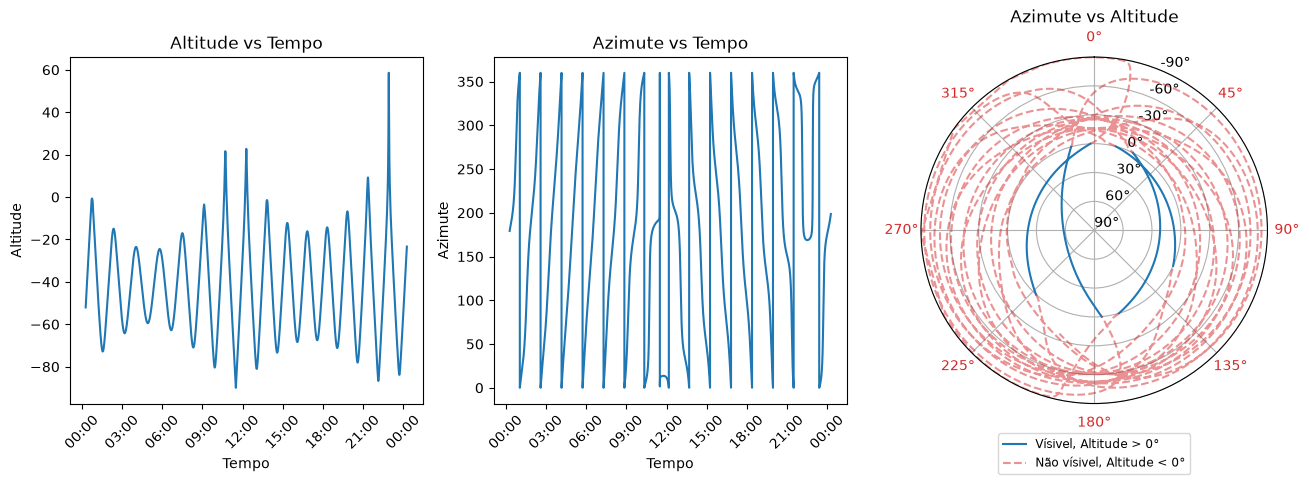

In [133]:
fig = plt.figure(figsize=(15.5,4.5))

#plot altitude
ax1 = fig.add_subplot(1,3,1)
ax1.plot(times, posat2_alt)
ax1.set_title("Altitude vs Tempo")
ax1.set_ylabel("Altitude")

#plot azimute
ax2 = fig.add_subplot(1,3,2)
ax2.plot(times, posat2_az)
ax2.set_title("Azimute vs Tempo")
ax2.set_ylabel("Azimute")

#Faz a formatação dos dois primeiros plots
format = mdates.DateFormatter("%H:%M")
for ax in (ax1, ax2): 
    ax.set_xlabel("Tempo")
    ax.xaxis.set_major_formatter(format)
    ax.tick_params(axis="x", rotation=45)

#--------------------//-----------------------

#plot azimute vs altitude
ax3 = fig.add_subplot(1,3,3, projection="polar")

alt = np.asarray(posat2_alt)
az = np.asarray(posat2_az)

#cria listas distintas para altitudes negativas e positivas
#na lista de pontos de altitude negativa são marcados como "not a number"
#para evitar que o plot da altitute ligue dois pontos de altitude positiva
#que têm pontos de altitude negativa entre eles
#faz o mesmo para a lista de altitudes negativas
alt_above = np.where(alt >= 0, alt, np.nan)
alt_below = np.where(alt < 0, alt, np.nan)

ax3.set_title("Azimute vs Altitude")

#coloca os 0° do azimute a norte e a crescer no sentido horario
ax3.set_theta_zero_location("N")
ax3.set_theta_direction(-1)

ax3.set_rlim(-90.01, 90)
ax3.set_rticks([-90, -60, -30, 0, 30, 60, 90])
ax3.tick_params(axis="x", labelcolor="C3")
ax3.set_yticklabels(["90°", "60°", "30°", "0°", "-30°", "-60°", "-90°"])

ax3.plot(np.deg2rad(az),-alt_above, label="Vísivel, Altitude > 0°")
ax3.plot(np.deg2rad(az),-alt_below, label="Não vísivel, Altitude < 0°", 
         color="C3", linestyle="--", alpha=0.5)

ax3.legend(fontsize=8.3, loc="lower center", bbox_to_anchor=(0.5, -0.22))

plt.show()

<div class="alert alert-block alert-info">  


## <center>PART 2 -  Processing TLEs on the large scale </center>

Here is where you process the whole TLE file, propagate orbits, compute 3D cartesian positions of the satellites and write the output to a file for opening in other analsys software. 

Below, I provide a utility function for reading the TLE file into a list of _EarthSatellite_ objects. It is for you to understand how the function works or use another method.

</div>


In [87]:
# Auxiliary function for reading 3LE files

def loadTLE(filename):
    """ Loads a TLE file and creates a list of satellites."""
    f = open(filename)
    satlist = []
    l1 = f.readline()
    while l1:
        l2 = f.readline()
        l3 = f.readline()
        sat = ephem.readtle(l1,l2,l3)
        satlist.append(sat)
        l1 = f.readline()

    f.close()
    print("%i satellites loaded into list"%len(satlist))
    return satlist

<div class="alert alert-block alert-info">  


### Read a TLE file

Read the TLEs from the file provided for this activity into a list of _EarthSatellite_ objects

</div>


In [88]:
sats = loadTLE("3le_03112026.txt")

32512 satellites loaded into list


<div class="alert alert-block alert-info">  

### Compute orbits and create arrays of X,Y,Z cartesian positions relative to the centre of the Earth of the objects read above

The computations are for one fixed date of your choice. You may use the observer and a date defined in the beginning of the report, or set a new location and date (clearly indicated).

Sometimes, _ephem_ will not compute the positions and exits with an error. This is often due to the old date of some TLEs. To overcome this unwanted termination, you will have to capture those exceptions and eliminate the problematic satellites from the list. Print on the screen the names of the satellites that have been discarded.

</div>


In [ ]:
xx, yy, zz = [], [], []

for i in range(0, len(sats)):
    sats[i].compute(obs)
    try:
        radius = ephem.earth_radius + sats[i].elevation
        x = radius*np.cos(sats[i].sublong)*np.cos(sats[i].sublat)
        y = radius*np.sin(sats[i].sublong)*np.cos(sats[i].sublat)
        z = radius*np.sin(sats[i].sublat)
    except RuntimeError:
        print("%i apagado %s: não foi possível calcular a posição do objeto na data %s" % (i,sats[i].name,obs.date))
        x=y=z = float('nan')
    xx.append(x)
    yy.append(y)
    zz.append(z)

xx = np.array(xx)
yy = np.array(yy)
zz = np.array(zz)

<div class="alert alert-block alert-info">  


### Plot cartesian XYZ positions in 3D

There are some outliers at great distances. Get rid of them to provide a good view of the LEO and GEO environments.

Note: You might get some warnings which can be safely muted with:
np.warnings.filterwarnings('ignore')

</div>


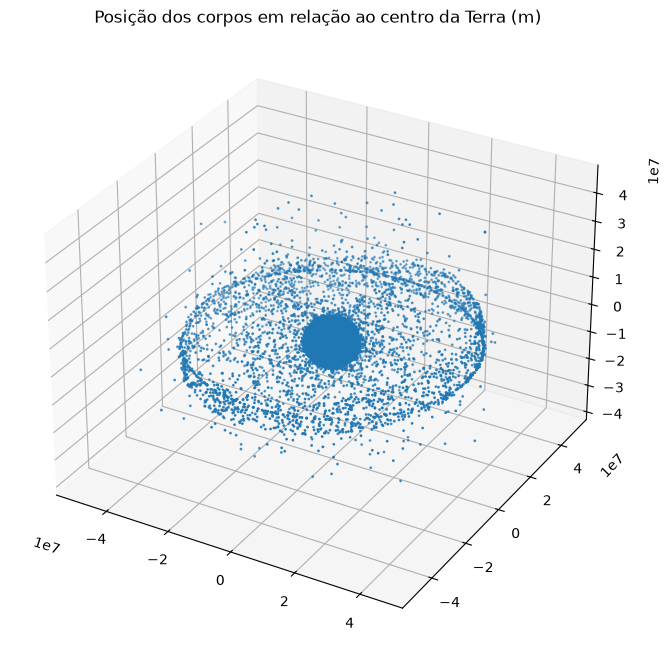

In [99]:
fig = plt.figure(figsize=(20,8))
ax = fig.add_subplot(projection="3d")
ax.set_title("Posição dos corpos em relação ao centro da Terra (m)")

maxrad = 5.0e7
mask = (abs(xx) < maxrad)&(abs(yy) < maxrad)&(abs(zz) < maxrad) 

ax.scatter3D(xx[mask], yy[mask], zz[mask], s=1)

plt.show()

<div class="alert alert-block alert-info">  


### Export results to a csv file

You were able to do a 3D plot showing the Earth's orbital environments. That was nice. But now we want to export the data to a file to continue exploring them with more specialised interactive visualisation software. 

For that, export the data from the orbit computation, as well as X,Y,Z to a CSV file. Include a header identifying the columns listed.  

Note: You may also make the header more human friendy by changing the names in some fields (e.g. _n -> mean motion). Remember that the "help" instruction provides a description of the variables.

</div>


<div class="alert alert-block alert-info">  

Check all went fine: Print the header and first lines to the screen
</div>


<div class="alert alert-block alert-info">  


### Quick analyis with TOPCAT

* Open the csv file in TOPCAT
* Make a 3D plot of X,Y,Z to show the LEO/MEO/GEO environments
* Make a (2D) scatter plot of eccentricity vs mean_motion
* Create a subset of the data by selecting a region you find interesting in the 2D plot
* Show how this subset appears distributed in the 3D plot
* Take a screenshot of your Desktop with the TOPCAT plots clearly seen and display it in the markdown cell below (double click on the example image from Gaia DR3)

</div>

![This image is a placeholder. Change it](Gaia_eDR3.png)